Standardization

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset directly from the CampusX GitHub repository
url = "https://raw.githubusercontent.com/campusx-official/100-days-of-machine-learning/main/day24-standardization/Social_Network_Ads.csv"
df = pd.read_csv(url)

# Keep only Age, EstimatedSalary, and Purchased
df = df.iloc[:, 2:]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    df.drop('Purchased', axis=1),
    df['Purchased'],
    test_size=0.3,
    random_state=0
)

print(X_train.shape, X_test.shape)

(280, 2) (120, 2)


In [2]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit the scaler to the train set (learns mean and std)
scaler.fit(X_train)
print("Learned Means:", scaler.mean_)

# Transform both train and test sets
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert NumPy arrays back to DataFrames
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

# Verify that Mean = 0 and Std = 1 after scaling
print("Before Scaling:\n", np.round(X_train.describe(), 1))
print("\nAfter Scaling:\n", np.round(X_train_scaled.describe(), 1))

Learned Means: [3.78642857e+01 6.98071429e+04]
Before Scaling:
          Age  EstimatedSalary
count  280.0            280.0
mean    37.9          69807.1
std     10.2          34641.2
min     18.0          15000.0
25%     30.0          43000.0
50%     37.0          70500.0
75%     46.0          88000.0
max     60.0         150000.0

After Scaling:
          Age  EstimatedSalary
count  280.0            280.0
mean     0.0              0.0
std      1.0              1.0
min     -1.9             -1.6
25%     -0.8             -0.8
50%     -0.1              0.0
75%      0.8              0.5
max      2.2              2.3


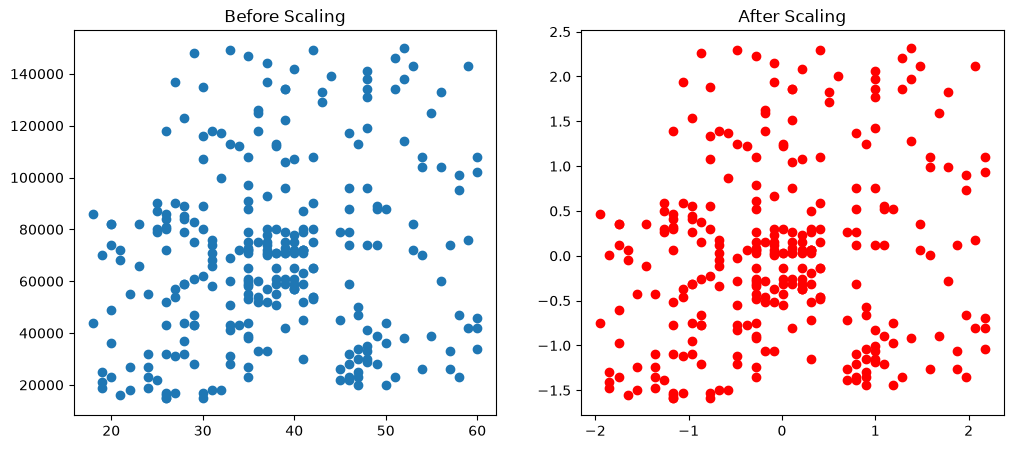

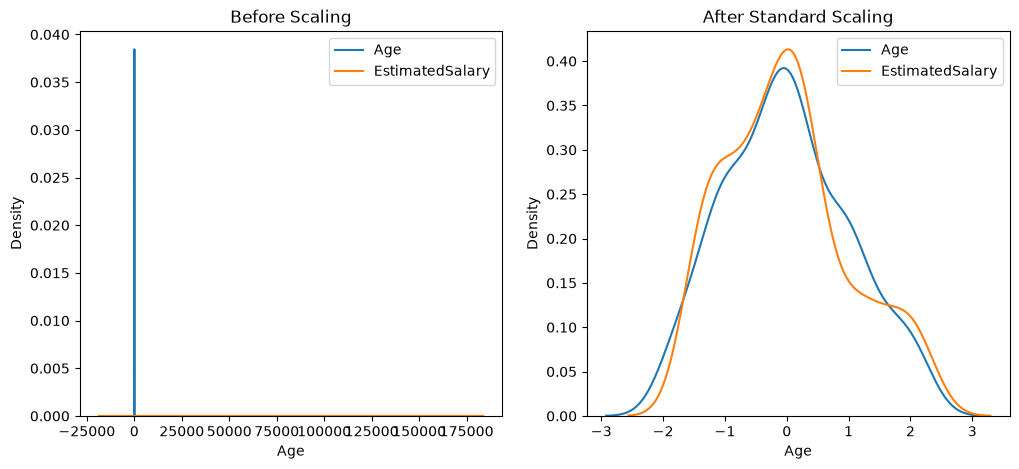

In [3]:
# 1. Scatter Plot: Before vs After Scaling
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(X_train['Age'], X_train['EstimatedSalary'])
ax1.set_title("Before Scaling")
ax2.scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'], color='red')
ax2.set_title("After Scaling")
plt.show()

# 2. PDF / KDE Plot: Comparing Feature Scales Together
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Age'], ax=ax1, label='Age')
sns.kdeplot(X_train['EstimatedSalary'], ax=ax1, label='EstimatedSalary')
ax1.legend()

ax2.set_title('After Standard Scaling')
sns.kdeplot(X_train_scaled['Age'], ax=ax2, label='Age')
sns.kdeplot(X_train_scaled['EstimatedSalary'], ax=ax2, label='EstimatedSalary')
ax2.legend()
plt.show()

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# --- Logistic Regression ---
lr = LogisticRegression()
lr_scaled = LogisticRegression()

lr.fit(X_train, y_train)
lr_scaled.fit(X_train_scaled, y_train)

y_pred = lr.predict(X_test)
y_pred_scaled = lr_scaled.predict(X_test_scaled)

print("LR Accuracy (Actual):", accuracy_score(y_test, y_pred))
print("LR Accuracy (Scaled):", accuracy_score(y_test, y_pred_scaled))

# --- Decision Tree ---
dt = DecisionTreeClassifier()
dt_scaled = DecisionTreeClassifier()

dt.fit(X_train, y_train)
dt_scaled.fit(X_train_scaled, y_train)

y_pred_dt = dt.predict(X_test)
y_pred_dt_scaled = dt_scaled.predict(X_test_scaled)

print("DT Accuracy (Actual):", accuracy_score(y_test, y_pred_dt))
print("DT Accuracy (Scaled):", accuracy_score(y_test, y_pred_dt_scaled))

LR Accuracy (Actual): 0.875
LR Accuracy (Scaled): 0.8666666666666667
DT Accuracy (Actual): 0.875
DT Accuracy (Scaled): 0.8666666666666667


In [5]:
# Inject 3 extreme outlier rows
outliers = pd.DataFrame({
    'Age': [5, 90, 95],
    'EstimatedSalary': [1000, 250000, 350000],
    'Purchased': [0, 1, 1]
})
df_outliers = pd.concat([df, outliers], ignore_index=True)

# Re-run split and scaling on df_outliers to see outliers retained in scatter plots

Normalization

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load wine dataset from CampusX GitHub repository
url = "https://raw.githubusercontent.com/campusx-official/100-days-of-machine-learning/main/day25-normalization/wine_data.csv"
df = pd.read_csv(url, header=None, usecols=[0, 1, 2])
df.columns = ['Class label', 'Alcohol', 'Malic acid']

print(df.head())

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    df.drop('Class label', axis=1),
    df['Class label'],
    test_size=0.3,
    random_state=0
)

   Class label  Alcohol  Malic acid
0            1    14.23        1.71
1            1    13.20        1.78
2            1    13.16        2.36
3            1    14.37        1.95
4            1    13.24        2.59


In [7]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

# Fit the scaler to the train set (learns min and max)
scaler.fit(X_train)

# Transform train and test sets
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert NumPy arrays back to DataFrames
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

# Verify that Min = 0.0 and Max = 1.0 after scaling
print("Before Scaling:\n", np.round(X_train.describe(), 1))
print("\nAfter MinMax Scaling:\n", np.round(X_train_scaled.describe(), 1))

Before Scaling:
        Alcohol  Malic acid
count    124.0       124.0
mean      13.0         2.4
std        0.8         1.1
min       11.0         0.9
25%       12.4         1.6
50%       13.0         1.9
75%       13.6         3.2
max       14.8         5.6

After MinMax Scaling:
        Alcohol  Malic acid
count    124.0       124.0
mean       0.5         0.3
std        0.2         0.2
min        0.0         0.0
25%        0.4         0.2
50%        0.5         0.2
75%        0.7         0.5
max        1.0         1.0


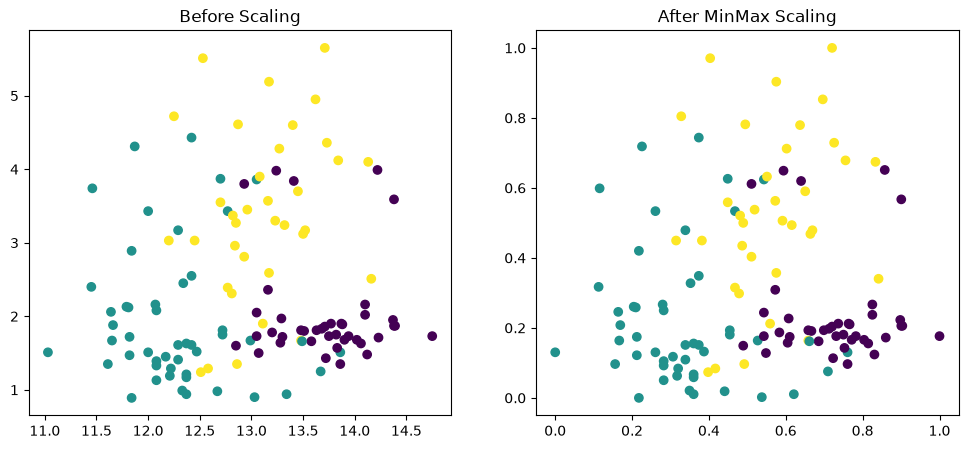

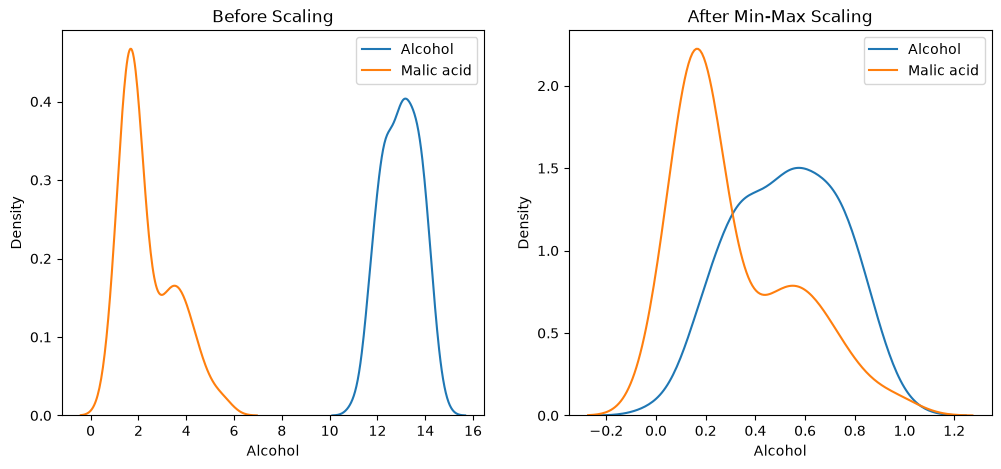

In [8]:
# 1. Scatter Plot: Before vs After MinMax Scaling
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(X_train['Alcohol'], X_train['Malic acid'], c=y_train)
ax1.set_title("Before Scaling")
ax2.scatter(X_train_scaled['Alcohol'], X_train_scaled['Malic acid'], c=y_train)
ax2.set_title("After MinMax Scaling")
plt.show()

# 2. KDE Plot: Comparing Alcohol and Malic Acid Distributions
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Alcohol'], ax=ax1, label='Alcohol')
sns.kdeplot(X_train['Malic acid'], ax=ax1, label='Malic acid')
ax1.legend()

ax2.set_title('After Min-Max Scaling')
sns.kdeplot(X_train_scaled['Alcohol'], ax=ax2, label='Alcohol')
sns.kdeplot(X_train_scaled['Malic acid'], ax=ax2, label='Malic acid')
ax2.legend()
plt.show()

In [9]:
from sklearn.preprocessing import MaxAbsScaler, RobustScaler

# For sparse matrices (divides by |x_max|, preserving zeros):
max_abs_scaler = MaxAbsScaler()
X_train_maxabs = max_abs_scaler.fit_transform(X_train)

# For datasets with outliers (uses Median and IQR: (x_i - median) / (Q3 - Q1)):
robust_scaler = RobustScaler()
X_train_robust = robust_scaler.fit_transform(X_train)